
ORIGINAL DATASET:
    Area  Bedrooms  Age  Price
0   1000         2   10     20
1   1200         2    8     25
2   1500         3    7     30
3   1800         3    6     35
4   2000         3    5     40
5   2200         4    5     43
6   2500         4    4     48
7   2700         4    4     52
8   3000         4    3     55
9   3200         5    3     60
10  3500         5    2     65
11  3700         5    2     68
12  4000         5    2     72
13  4200         6    1     78
14  4500         6    1     85

========== SIMPLE LINEAR REGRESSION ==========
Intercept: 3.798973318968251
Coefficient: 0.017595538373787946

Simple Linear Regression Evaluation
R2 Score: 0.9979056947386342
RMSE: 0.9609141062955059


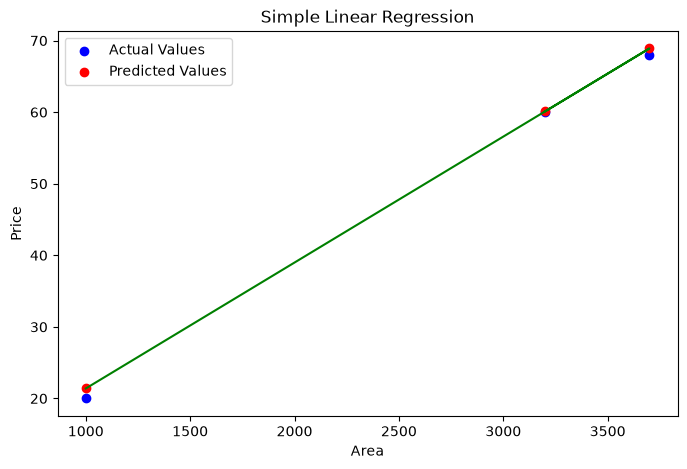


========== MULTIPLE LINEAR REGRESSION ==========
Intercept: -0.17205145831290025
Coefficients:
Area : 0.016383187665717384
Bedrooms : 1.5550427182559146
Age : 0.24133359520769893

Multiple Linear Regression Evaluation
R2 Score: 0.9969218753788889
RMSE: 1.1649510479257097

========== OLS REGRESSION SUMMARY ==========
                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                     969.5
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.39e-10
Time:                        12:23:35   Log-Likelihood:                -16.615
No. Observations:                  12   AIC:                             41.23
Df Residuals:                       8   BIC:                             43.17
Df Model:                           3            

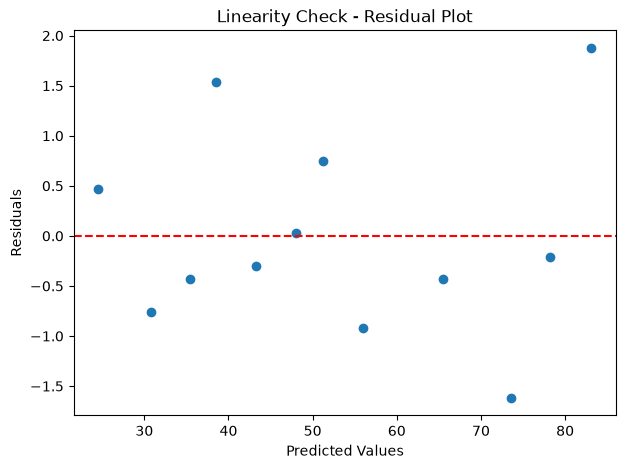

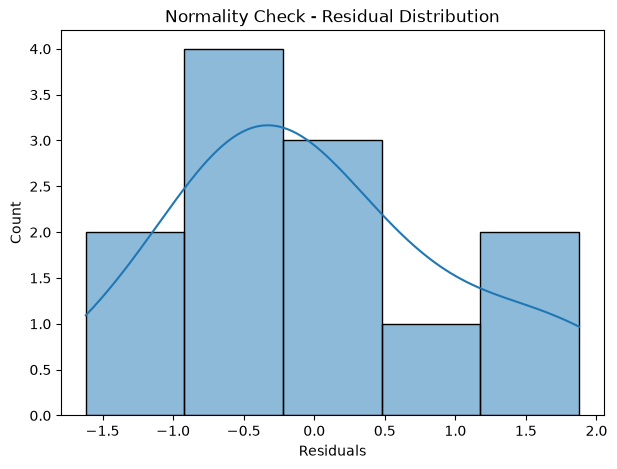


Shapiro-Wilk Normality Test
Statistic: 0.9554735599231657
P-value: 0.7177981624771548
Residuals are consistent with normality.

Breusch-Pagan Test
LM Statistic: 5.713430728386415
P-value: 0.12641599240658186
No significant evidence of heteroscedasticity.

Variance Inflation Factor (VIF)
    Feature        VIF
0     const   1.000000
1      Area  31.442817
2  Bedrooms  16.771306
3       Age  23.714328

Durbin-Watson Test
DW Score: 0.8092611704163913
Possible autocorrelation; investigate further.

========== MODEL COMPARISON ==========
                        Model  R2 Score      RMSE
0    Simple Linear Regression  0.997906  0.960914
1  Multiple Linear Regression  0.996922  1.164951

========== PROGRAM COMPLETED SUCCESSFULLY ==========


In [2]:

# ==========================================================
# SIMPLE AND MULTIPLE LINEAR REGRESSION
# MODEL BUILDING, ASSUMPTION CHECKING AND EVALUATION
# ==========================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
import statsmodels.api as sm

from scipy.stats import shapiro


# 2. CREATE DATASET

data = {
    'Area': [1000, 1200, 1500, 1800, 2000,
             2200, 2500, 2700, 3000, 3200,
             3500, 3700, 4000, 4200, 4500],

    'Bedrooms': [2, 2, 3, 3, 3,
                 4, 4, 4, 4, 5,
                 5, 5, 5, 6, 6],

    'Age': [10, 8, 7, 6, 5,
            5, 4, 4, 3, 3,
            2, 2, 2, 1, 1],

    'Price': [20, 25, 30, 35, 40,
              43, 48, 52, 55, 60,
              65, 68, 72, 78, 85]
}

df = pd.DataFrame(data)

print("\nORIGINAL DATASET:")
print(df)


# ==========================================================
# PART A: SIMPLE LINEAR REGRESSION
# ==========================================================

# 3. SELECT INPUT AND OUTPUT

X = df[['Area']]
y = df['Price']


# 4. SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


# 5. BUILD SIMPLE LINEAR REGRESSION MODEL

simple_model = LinearRegression()

simple_model.fit(X_train, y_train)


# 6. PREDICTION

y_pred_simple = simple_model.predict(X_test)


# 7. MODEL COEFFICIENTS

print("\n========== SIMPLE LINEAR REGRESSION ==========")

print("Intercept:", simple_model.intercept_)

print("Coefficient:", simple_model.coef_[0])


# 8. MODEL EVALUATION

r2_simple = r2_score(y_test, y_pred_simple)

rmse_simple = np.sqrt(
    mean_squared_error(y_test, y_pred_simple)
)

print("\nSimple Linear Regression Evaluation")

print("R2 Score:", r2_simple)

print("RMSE:", rmse_simple)


# 9. VISUALIZATION

plt.figure(figsize=(8, 5))

plt.scatter(X_test, y_test, color='blue',
            label='Actual Values')

plt.scatter(X_test, y_pred_simple, color='red',
            label='Predicted Values')

plt.plot(X_test, y_pred_simple, color='green')

plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Simple Linear Regression')

plt.legend()
plt.show()


# ==========================================================
# PART B: MULTIPLE LINEAR REGRESSION
# ==========================================================

# 10. SELECT MULTIPLE INPUT FEATURES

X = df[['Area', 'Bedrooms', 'Age']]
y = df['Price']


# 11. SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


# 12. BUILD MULTIPLE LINEAR REGRESSION MODEL

multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)


# 13. PREDICTION

y_pred_multiple = multiple_model.predict(X_test)


# 14. MODEL COEFFICIENTS

print("\n========== MULTIPLE LINEAR REGRESSION ==========")

print("Intercept:", multiple_model.intercept_)

print("Coefficients:")

for feature, coefficient in zip(
    X.columns, multiple_model.coef_
):
    print(feature, ":", coefficient)


# 15. MODEL EVALUATION

r2_multiple = r2_score(y_test, y_pred_multiple)

rmse_multiple = np.sqrt(
    mean_squared_error(y_test, y_pred_multiple)
)

print("\nMultiple Linear Regression Evaluation")

print("R2 Score:", r2_multiple)

print("RMSE:", rmse_multiple)


# ==========================================================
# PART C: CHECKING REGRESSION ASSUMPTIONS
# ==========================================================

# 16. CREATE OLS MODEL FOR STATISTICAL TESTS

X_train_constant = sm.add_constant(X_train)

ols_model = sm.OLS(
    y_train,
    X_train_constant
).fit()

print("\n========== OLS REGRESSION SUMMARY ==========")

print(ols_model.summary())


# 17. RESIDUAL CALCULATION

y_train_pred = multiple_model.predict(X_train)

residuals = y_train - y_train_pred


# 18. ASSUMPTION 1: LINEARITY

plt.figure(figsize=(7, 5))

plt.scatter(y_train_pred, residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Values')
plt.ylabel('Residuals')

plt.title('Linearity Check - Residual Plot')

plt.show()


# 19. ASSUMPTION 2: NORMALITY OF RESIDUALS

plt.figure(figsize=(7, 5))

sns.histplot(residuals, kde=True)

plt.title('Normality Check - Residual Distribution')

plt.xlabel('Residuals')

plt.show()

shapiro_test = shapiro(residuals)

print("\nShapiro-Wilk Normality Test")

print("Statistic:", shapiro_test.statistic)

print("P-value:", shapiro_test.pvalue)

if shapiro_test.pvalue > 0.05:
    print("Residuals are consistent with normality.")
else:
    print("Evidence suggests residuals are not normally distributed.")


# 20. ASSUMPTION 3: HOMOSCEDASTICITY

bp_test = het_breuschpagan(
    ols_model.resid,
    ols_model.model.exog
)

print("\nBreusch-Pagan Test")

print("LM Statistic:", bp_test[0])

print("P-value:", bp_test[1])

if bp_test[1] > 0.05:
    print("No significant evidence of heteroscedasticity.")
else:
    print("Evidence of heteroscedasticity detected.")


# 21. ASSUMPTION 4: MULTICOLLINEARITY (VIF)

X_vif = sm.add_constant(X_train)

vif_data = pd.DataFrame()

vif_data['Feature'] = X_vif.columns

vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

print("\nVariance Inflation Factor (VIF)")

print(vif_data)


# 22. ASSUMPTION 5: INDEPENDENCE OF ERRORS

dw_score = durbin_watson(ols_model.resid)

print("\nDurbin-Watson Test")

print("DW Score:", dw_score)

if 1.5 <= dw_score <= 2.5:
    print("No strong indication of autocorrelation.")
else:
    print("Possible autocorrelation; investigate further.")


# ==========================================================
# PART D: COMPARE BOTH MODELS
# ==========================================================

print("\n========== MODEL COMPARISON ==========")

comparison = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression'
    ],

    'R2 Score': [
        r2_simple,
        r2_multiple
    ],

    'RMSE': [
        rmse_simple,
        rmse_multiple
    ]
})

print(comparison)


# 23. FINAL RESULT

print("\n========== PROGRAM COMPLETED SUCCESSFULLY ==========")
